## Feature Descriptions

**Source:** [Default of Credit Card Clients Dataset](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset
| Feature | Description |
|---|---|
| `ID` | Unique client identifier |
| `LIMIT_BAL` | Credit amount given in NT dollars (includes individual and family/supplementary credit) |
| `SEX` | Gender — 1=Male, 2=Female |
| `EDUCATION` | Education level — 1=Graduate school, 2=University, 3=High school, 4=Others, 5–6=Unknown |
| `MARRIAGE` | Marital status — 1=Married, 2=Single, 3=Others |
| `AGE` | Age in years |
| `PAY_0` | Repayment status, Sep 2005 — -1=Paid duly, 1–8=Delay by N months, 9=Delay 9+ months |
| `PAY_2` | Repayment status, Aug 2005 (same scale as PAY_0) |
| `PAY_3` | Repayment status, Jul 2005 (same scale as PAY_0) |
| `PAY_4` | Repayment status, Jun 2005 (same scale as PAY_0) |
| `PAY_5` | Repayment status, May 2005 (same scale as PAY_0) |
| `PAY_6` | Repayment status, Apr 2005 (same scale as PAY_0) |
| `BILL_AMT1` | Bill statement amount, Sep 2005 (NT dollar) |
| `BILL_AMT2` | Bill statement amount, Aug 2005 (NT dollar) |
| `BILL_AMT3` | Bill statement amount, Jul 2005 (NT dollar) |
| `BILL_AMT4` | Bill statement amount, Jun 2005 (NT dollar) |
| `BILL_AMT5` | Bill statement amount, May 2005 (NT dollar) |
| `BILL_AMT6` | Bill statement amount, Apr 2005 (NT dollar) |
| `PAY_AMT1` | Previous payment amount, Sep 2005 (NT dollar) |
| `PAY_AMT2` | Previous payment amount, Aug 2005 (NT dollar) |
| `PAY_AMT3` | Previous payment amount, Jul 2005 (NT dollar) |
| `PAY_AMT4` | Previous payment amount, Jun 2005 (NT dollar) |
| `PAY_AMT5` | Previous payment amount, May 2005 (NT dollar) |
| `PAY_AMT6` | Previous payment amount, Apr 2005 (NT dollar) |
| `default.payment.next.month` | **Target variable** — Default next month? 1=Yes, 0=No |

In [1]:
import pandas as pd
#load the dataset
df= pd.read_csv('../data/UCI_Credit_Card.csv')
#check the structure with what the source said
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## EDA & Preprocessing

In [2]:
#drop ID
df = df.drop('ID', axis = 1)
#In EDUCATION, 0, 5, and 6 should be coded as 4 ("other")
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
#In MARRIAGE, 0 can be treated as 3 ("other")
df['MARRIAGE'] = df['MARRIAGE'].replace({0:3})

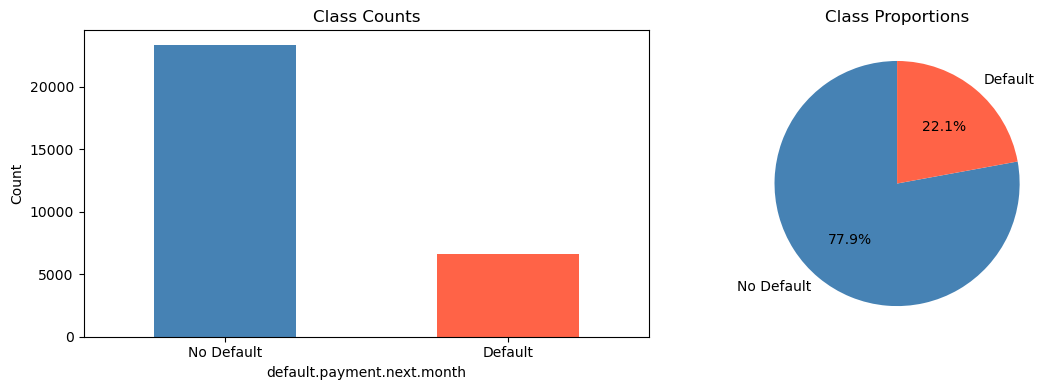

In [3]:
#EDA visualization
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['default.payment.next.month'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue', 'tomato'])
axes[0].set_title('Class Counts')
axes[0].set_xticklabels(['No Default', 'Default'], rotation=0)
axes[0].set_ylabel('Count')

df['default.payment.next.month'].value_counts().plot(
    kind='pie', ax=axes[1], labels=['No Default', 'Default'],
    autopct='%1.1f%%', colors=['steelblue', 'tomato'], startangle=90
)
axes[1].set_title('Class Proportions')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

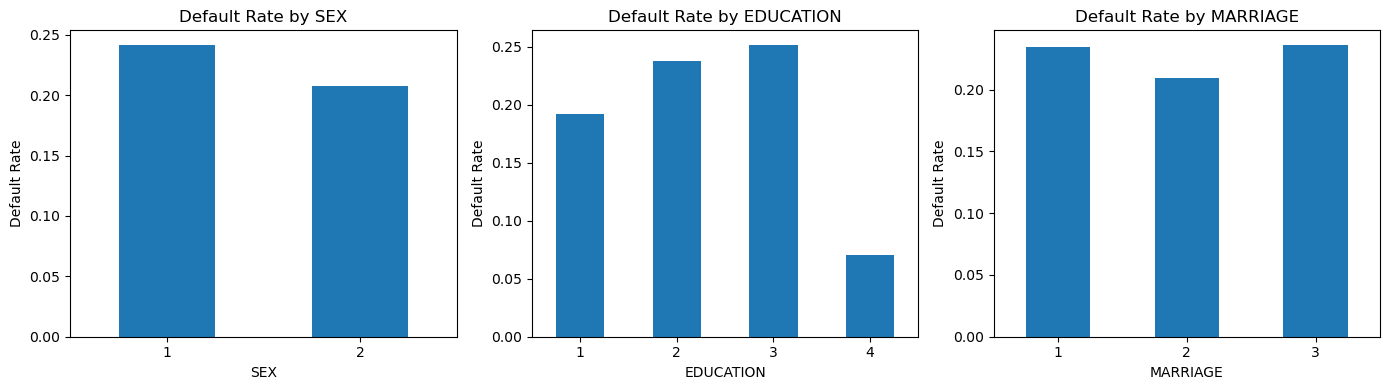

In [4]:
cat_cols = ['SEX', 'EDUCATION', 'MARRIAGE']

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, cat_cols):
    df.groupby(col)['default.payment.next.month'].mean().plot(kind='bar', ax=ax)
    ax.set_title(f'Default Rate by {col}')
    ax.set_ylabel('Default Rate')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

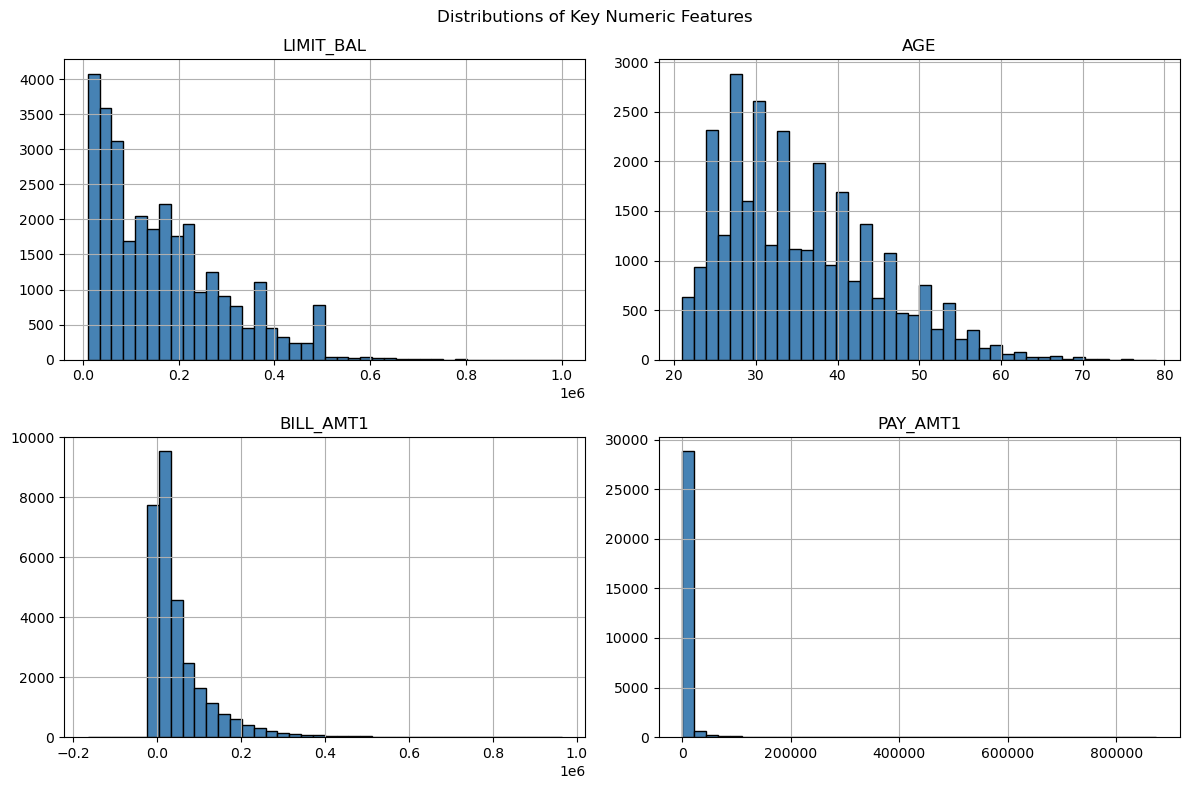

In [5]:
#Showing skewness in some of our features
num_cols = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']

df[num_cols].hist(bins=40, figsize=(12, 8), color='steelblue', edgecolor='black')
plt.suptitle('Distributions of Key Numeric Features')
plt.tight_layout()
plt.show()

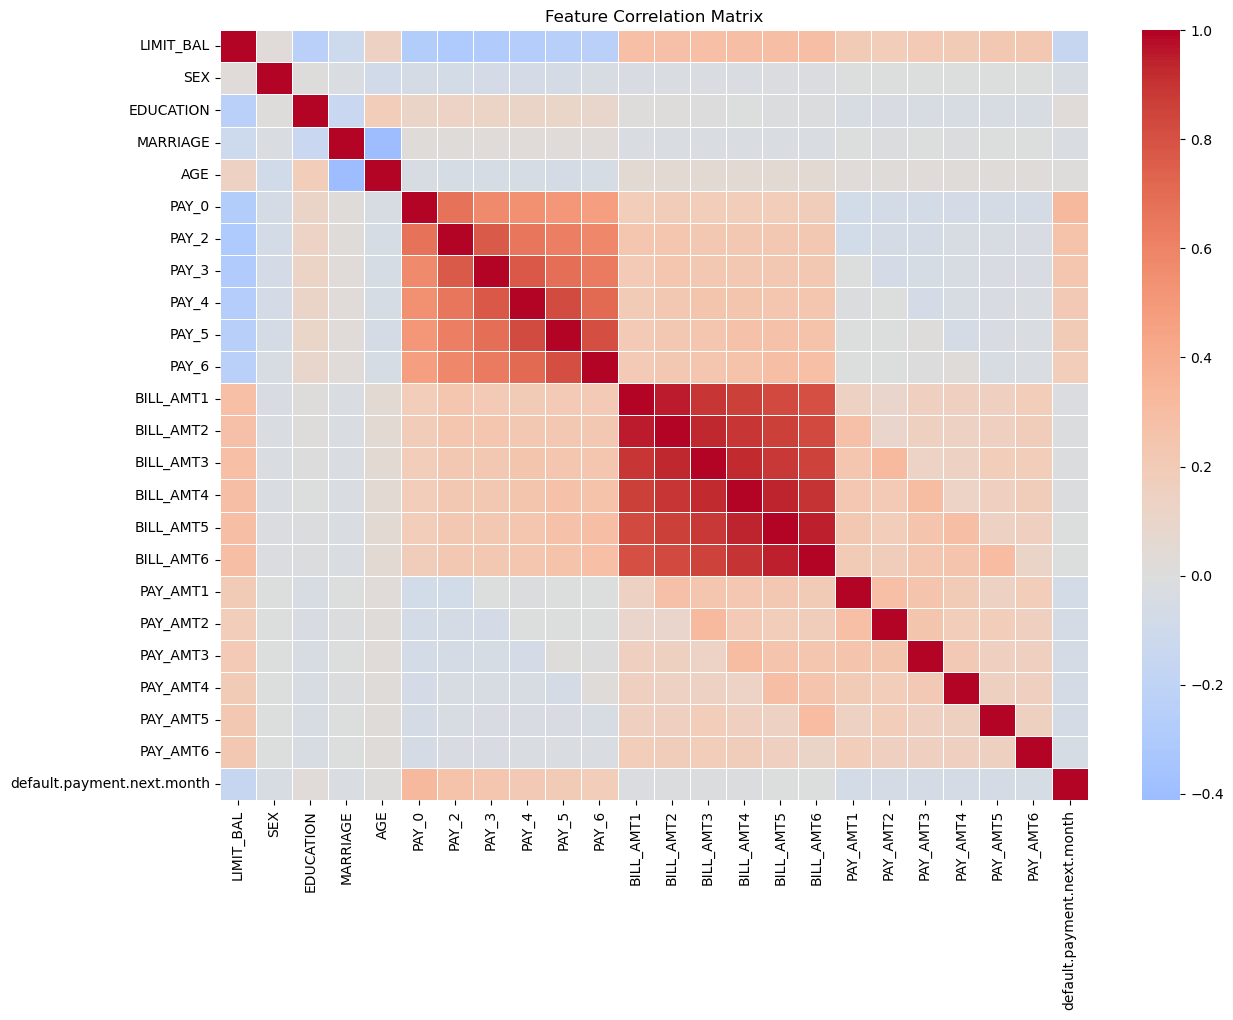

In [6]:
import seaborn as sns

plt.figure(figsize=(14, 10))
corr = df.corr()   # ← no need to drop ID, it's already gone
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False, linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.show()


In [7]:
# Post EDA feature engineering 
# Full feature set (Neural Net & Random Forest)
X_full = df.drop(columns='default.payment.next.month')

# Reduced feature set (KNN)
bill_cols = ['BILL_AMT1','BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5','BILL_AMT6']
pay_cols  = ['PAY_AMT1','PAY_AMT2','PAY_AMT3','PAY_AMT4','PAY_AMT5','PAY_AMT6']

X_knn = df.drop(columns=bill_cols + pay_cols + ['default.payment.next.month']).copy()
X_knn['BILL_AMT_mean'] = df[bill_cols].mean(axis=1)
X_knn['PAY_AMT_mean']  = df[pay_cols].mean(axis=1)

y = df['default.payment.next.month']

## Choices Made

### Data Cleaning
The `ID` column was dropped as it is a unique identifier with no predictive value.

Two categorical features contained undocumented codes not listed in the original dataset description:
- **`EDUCATION`**: Codes `0`, `5`, and `6` are not defined in the source documentation and were recoded to `4` ("other")
- **`MARRIAGE`**: Code `0` is similarly undocumented and was recoded to `3` ("other")

### Class Imbalance
The target variable (`default.payment.next.month`) is imbalanced — approximately **77.9% non-default vs. 22.1% default**.
This imbalance is important to account for during modeling (via stratified splitting)
to prevent the model from simply predicting the majority class.

### Categorical Feature Analysis
Default rates were examined across `SEX`, `EDUCATION`, and `MARRIAGE` to identify whether these demographic
features have any "at-a-glance" significance. Notably:
- Males (SEX=1) default at a slightly higher rate than females
- High school educated clients (EDUCATION=3) default at a higher rate than graduate school clients
- Clients with "other" marital status (MARRIAGE=3) show the highest default rate

### Numeric Feature Distributions
Histograms of somewhat arbitrary numeric features reveal right-skewed distributions in `LIMIT_BAL`, `BILL_AMT1`,
and `PAY_AMT1`, with a large concentration of values near zero. This skewness justifies the use
of `StandardScaler` prior to modeling, as KNN and Neural Networks are both sensitive to feature scale.

### Feature Engineering Post Correlation Analysis
A heatmap of pairwise feature correlations revealed two notable multicollinearity clusters:
- **`BILL_AMT1`–`BILL_AMT6`**: Highly correlated with one another, indicating significant redundancy
- **`PAY_AMT1`–`PAY_AMT6`**: Moderately correlated, though less severe than bill amounts
- **`PAY_0`** shows the strongest correlation with the target variable

To address multicollinearity, two separate feature sets were constructed:

- **`X_full`** (23 features): Retains all original columns — used for the **Neural Network** and **Random Forest**,
which are robust to correlated features
- **`X_knn`** (11 features): Replaces the 12 individual `BILL_AMT` and `PAY_AMT` columns with two summary
features (`BILL_AMT_mean`, `PAY_AMT_mean`) — used for **KNN**, which is sensitive to redundant dimensions
that distort distance calculations

## Train/Val/Test Split

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Train/Val/Test Split
# Full features
X_full_train, X_full_temp, y_train, y_temp = train_test_split(
    X_full, y, test_size=0.3, random_state=42, stratify=y)
X_full_val, X_full_test, y_val, y_test = train_test_split(
    X_full_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

# KNN features (different X)
X_knn_train, X_knn_temp, _, _ = train_test_split(
    X_knn, y, test_size=0.3, random_state=42, stratify=y)
X_knn_val, X_knn_test, _, _ = train_test_split(
    X_knn_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [9]:
# Scaling 
scaler_full = StandardScaler()
X_full_train = scaler_full.fit_transform(X_full_train)
X_full_val   = scaler_full.transform(X_full_val)
X_full_test  = scaler_full.transform(X_full_test)

scaler_knn = StandardScaler()
X_knn_train = scaler_knn.fit_transform(X_knn_train)
X_knn_val   = scaler_knn.transform(X_knn_val)
X_knn_test  = scaler_knn.transform(X_knn_test)

print("Full:", X_full_train.shape, X_full_val.shape, X_full_test.shape)
print("KNN: ", X_knn_train.shape, X_knn_val.shape, X_knn_test.shape)

Full: (21000, 23) (4500, 23) (4500, 23)
KNN:  (21000, 13) (4500, 13) (4500, 13)


In [10]:
#defining evaluation for ALL 3 models 
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve)
def evaluate_model(name, y_true, y_pred, y_prob):
    print(f"\n{name} Test Results")
    print("="*40)
    print(classification_report(y_true, y_pred, target_names=['No Default', 'Default']))
    print(f"AUC-ROC: {roc_auc_score(y_true, y_prob):.4f}")

## KNN 

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Tune k using validation set
k_values = range(1, 31)
val_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_knn_train, y_train)
    val_scores.append(accuracy_score(y_val, knn.predict(X_knn_val)))

best_k = k_values[val_scores.index(max(val_scores))]
print(f"Best k: {best_k}, Validation Accuracy: {max(val_scores):.4f}")

Best k: 28, Validation Accuracy: 0.8147


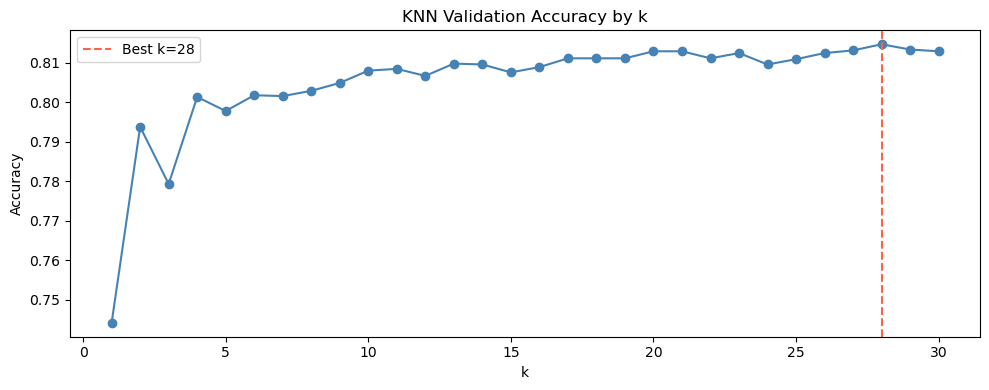

In [12]:
# Plot k vs. accuracy 
plt.figure(figsize=(10, 4))
plt.plot(k_values, val_scores, marker='o', color='steelblue')
plt.axvline(best_k, color='tomato', linestyle='--', label=f'Best k={best_k}')
plt.title('KNN Validation Accuracy by k')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# Fit model with best_k found above (this is still part of initial val exploration)
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_knn_train, y_train)

KNeighborsClassifier(n_neighbors=28)

In [14]:
#model evaluation (validation)
y_pred_knn_val = knn_model.predict(X_knn_val)
y_prob_knn_val = knn_model.predict_proba(X_knn_val)[:, 1]
evaluate_model("KNN Validation", y_val, y_pred_knn_val, y_prob_knn_val)


KNN Validation Test Results
              precision    recall  f1-score   support

  No Default       0.83      0.95      0.89      3505
     Default       0.66      0.33      0.44       995

    accuracy                           0.81      4500
   macro avg       0.75      0.64      0.66      4500
weighted avg       0.80      0.81      0.79      4500

AUC-ROC: 0.7447


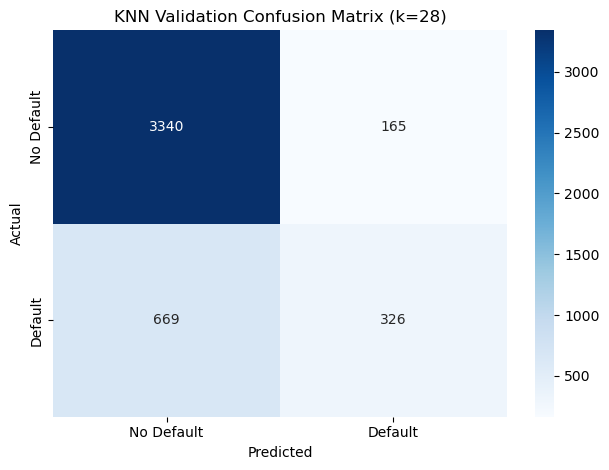

In [15]:
# Confusion matrix
cm = confusion_matrix(y_val, y_pred_knn_val)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Default', 'Default'],
            yticklabels=['No Default', 'Default'])
plt.title(f'KNN Validation Confusion Matrix (k={best_k})')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

### Hyperparameter tuning

In [16]:
from imblearn.over_sampling import SMOTE
import numpy as np
# Apply SMOTE to training data only
smote = SMOTE(random_state=42)
X_knn_train_sm, y_train_sm = smote.fit_resample(X_knn_train, y_train)

print(f"Original class counts: {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"Resampled class counts: {dict(zip(*np.unique(y_train_sm, return_counts=True)))}")

Original class counts: {np.int64(0): np.int64(16355), np.int64(1): np.int64(4645)}
Resampled class counts: {np.int64(0): np.int64(16355), np.int64(1): np.int64(16355)}


In [17]:
# Re-tune k on SMOTE-balanced training data
val_scores_sm = []
for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_knn_train_sm, y_train_sm)
    val_scores_sm.append(roc_auc_score(y_val, knn_temp.predict_proba(X_knn_val)[:, 1]))

best_k_sm = k_values[val_scores_sm.index(max(val_scores_sm))]
print(f"Best k after SMOTE: {best_k_sm}, Val AUC-ROC: {max(val_scores_sm):.4f}")

# Refit with best k
knn_smote = KNeighborsClassifier(n_neighbors=best_k_sm)
knn_smote.fit(X_knn_train_sm, y_train_sm)


Best k after SMOTE: 30, Val AUC-ROC: 0.7411


KNeighborsClassifier(n_neighbors=30)

In [18]:
# Evaluate on the ORIGINAL (unmodified) validation set
y_pred_knn_sm = knn_smote.predict(X_knn_val)
y_prob_knn_sm = knn_smote.predict_proba(X_knn_val)[:, 1]
evaluate_model("KNN + SMOTE Validation", y_val, y_pred_knn_sm, y_prob_knn_sm)


KNN + SMOTE Validation Test Results
              precision    recall  f1-score   support

  No Default       0.87      0.74      0.80      3505
     Default       0.41      0.62      0.49       995

    accuracy                           0.72      4500
   macro avg       0.64      0.68      0.65      4500
weighted avg       0.77      0.72      0.73      4500

AUC-ROC: 0.7411


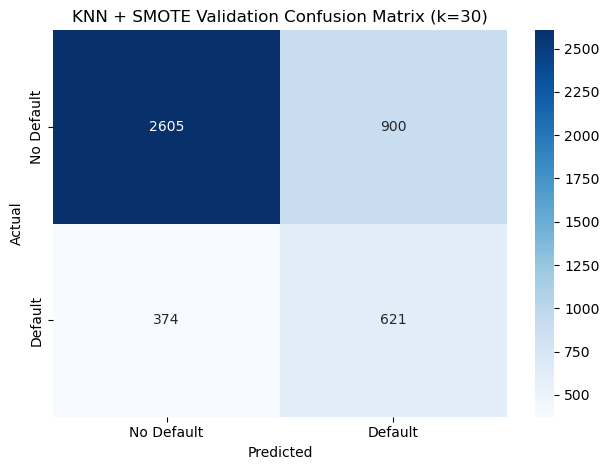

In [19]:
cm_sm = confusion_matrix(y_val, y_pred_knn_sm)
sns.heatmap(cm_sm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Default', 'Default'],
            yticklabels=['No Default', 'Default'])
plt.title(f'KNN + SMOTE Validation Confusion Matrix (k={best_k_sm})')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()


### KNN Results & Interpretation

The initial KNN model (k=28) achieved a validation accuracy of 81% but exhibited a severe recall-precision imbalance on the default class: precision of 0.66 but recall of only 0.33, yielding a default F1 of just 0.44 and an AUC-ROC of 0.7447. This revealed that the model was predominantly predicting the majority class (no default), and while it appeared accurate on the surface, it missed nearly two-thirds of actual defaulters — a critical failure in a credit risk context.


To address this, SMOTE was applied to the training data, synthetically oversampling the minority class from 4,645 to 16,355 observations. The SMOTE-augmented model (k=30) meaningfully shifted the precision-recall trade-off: default recall rose to 0.62 on validation and reached 0.6365 on the final test set, the highest of all three models, while default precision fell to 0.40 and default F1 settled at 0.49. Test set AUC-ROC came in at 0.7492, the lowest among the three models. This trade-off reflects the nature of SMOTE — by synthetically balancing the training distribution, the model becomes more sensitive to defaults but generates more false positives, limiting its overall discriminatory power. Given that KNN relies on proximity in high-dimensional space without an underlying probabilistic framework, and that its feature set was deliberately reduced to 11 dimensions to mitigate the curse of dimensionality, its discrimination ceiling remains lower than the ensemble and neural approaches.

## Random Forest

In [20]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest 
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',   # handles class imbalance
    random_state=42,
    n_jobs=-1                  # use all available cores
)
rf.fit(X_full_train, y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

In [21]:
# Evaluate on validation set
y_pred_rf_val = rf.predict(X_full_val)
y_prob_rf_val = rf.predict_proba(X_full_val)[:, 1]
evaluate_model("Random Forest Validation", y_val, y_pred_rf_val, y_prob_rf_val)


Random Forest Validation Test Results
              precision    recall  f1-score   support

  No Default       0.83      0.95      0.89      3505
     Default       0.65      0.33      0.44       995

    accuracy                           0.81      4500
   macro avg       0.74      0.64      0.66      4500
weighted avg       0.79      0.81      0.79      4500

AUC-ROC: 0.7574


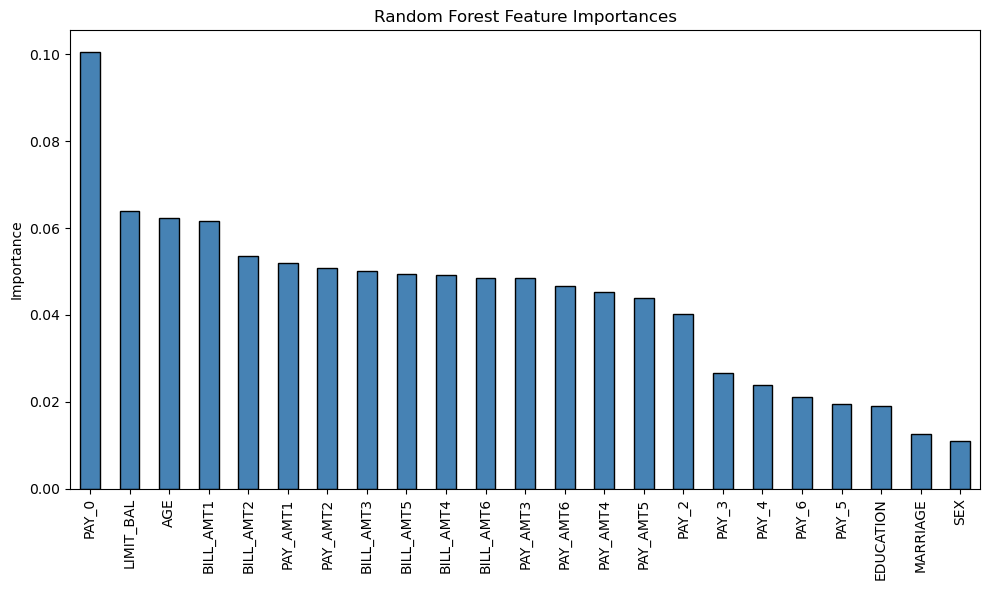

In [22]:
# Feature importance 
feature_names = df.drop(columns='default.payment.next.month').columns
importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Random Forest Feature Importances')
plt.ylabel('Importance')
plt.tight_layout()
plt.show()

### Hyperparameter tuning

In [23]:
from sklearn.model_selection import ParameterGrid

# Define hyperparameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', 0.5]  # ADD THIS
}

best_auc = 0
best_params = {}
results = []

for params in ParameterGrid(param_grid):
    rf_temp = RandomForestClassifier(
        **params,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    rf_temp.fit(X_full_train, y_train)
    auc = roc_auc_score(y_val, rf_temp.predict_proba(X_full_val)[:, 1])
    results.append({**params, 'val_auc': auc})
    
    if auc > best_auc:
        best_auc = auc
        best_params = params

print(f"Best Params: {best_params}")
print(f"Best Val AUC-ROC: {best_auc:.4f}")


Best Params: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 300}
Best Val AUC-ROC: 0.7767


In [24]:
# Refit with best hyperparameters
rf_tuned = RandomForestClassifier(
    **best_params,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_tuned.fit(X_full_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=4, n_estimators=300, n_jobs=-1,
                       random_state=42)

In [25]:
# Evaluate on validation set
y_pred_rf_tuned = rf_tuned.predict(X_full_val)
y_prob_rf_tuned = rf_tuned.predict_proba(X_full_val)[:, 1]
evaluate_model("Random Forest Tuned Validation", y_val, y_pred_rf_tuned, y_prob_rf_tuned)


Random Forest Tuned Validation Test Results
              precision    recall  f1-score   support

  No Default       0.87      0.85      0.86      3505
     Default       0.52      0.56      0.54       995

    accuracy                           0.79      4500
   macro avg       0.69      0.71      0.70      4500
weighted avg       0.79      0.79      0.79      4500

AUC-ROC: 0.7767


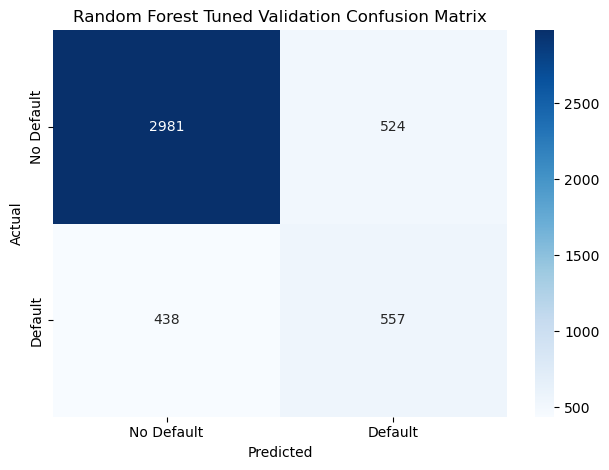

In [26]:
cm_rf_tuned = confusion_matrix(y_val, y_pred_rf_tuned)
sns.heatmap(cm_rf_tuned, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Default', 'Default'],
            yticklabels=['No Default', 'Default'])
plt.title('Random Forest Tuned Validation Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()


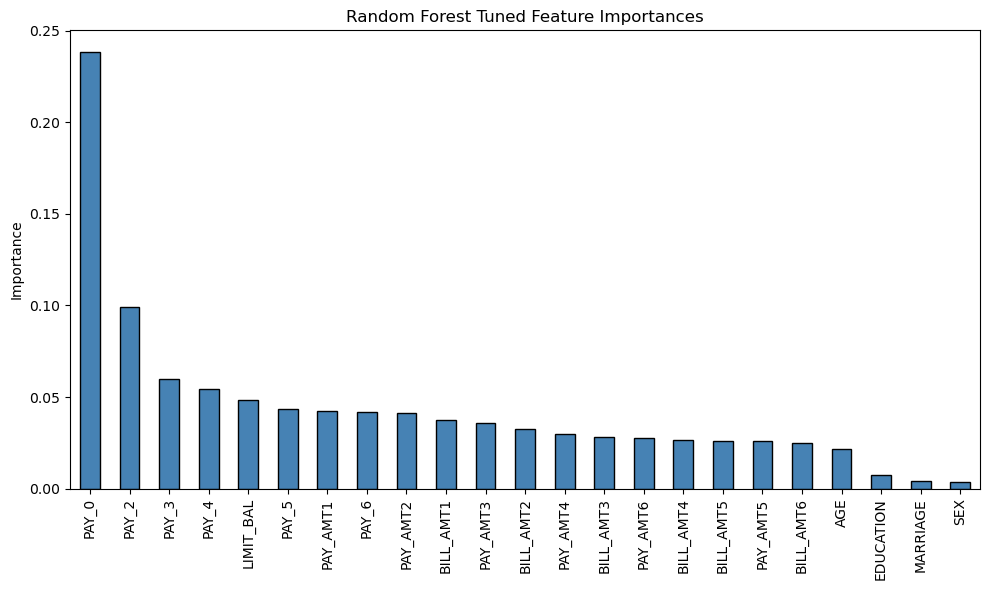

In [27]:
# Updated feature importances
feature_names = df.drop(columns='default.payment.next.month').columns
importances = pd.Series(rf_tuned.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Random Forest Tuned Feature Importances')
plt.ylabel('Importance')
plt.tight_layout()
plt.show()

### Random Forest Results & Interpretation

The default Random Forest (n_estimators=100, class_weight='balanced') produced a validation AUC-ROC of 0.7574, with a default recall of 0.33 and default F1 of 0.44 — identical in structure to the untuned KNN, indicating that without depth constraints the trees were still biased toward the majority class despite balanced weighting. Grid search over the hyperparameter space (n_estimators ∈ {100, 200, 300}, max_depth ∈ {None, 10, 20, 30}, min_samples_leaf ∈ {1, 2, 4}, max_features ∈ {'sqrt', 'log2', 0.5}) identified the optimal configuration as n_estimators=300, max_depth=10, min_samples_leaf=4, max_features='sqrt'. Capping tree depth at 10 was the single most impactful change, boosting validation AUC-ROC from 0.7574 to 0.7767 by preventing the unconstrained overfitting present in fully grown trees.

The tuned Random Forest on the final held-out test set achieved an accuracy of 78.9%, an AUC-ROC of 0.7771 — the highest of all three models — a default precision of 0.52, a default recall of 0.58, and a default F1 of 0.55. The class_weight='balanced' setting effectively compensated for the 77.9%/22.1% class imbalance without requiring synthetic oversampling, and feature importance analysis confirmed that PAY_0 was by far the most dominant predictor, consistent with its strong correlation to the target observed during EDA, followed distantly by other recent repayment status variables and credit limit. The Random Forest strikes the best overall balance between precision and recall for the default class across all threshold settings, making it the most practically reliable model in this project.


## Neural Network

In [28]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Build Model
model = keras.Sequential([
    layers.Input(shape=(X_full_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')   # binary classification
])
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,649 (14.25 KB)

 Trainable params: 3,649 (14.25 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
# Class weights for imbalance 
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))
print("Class weights:", class_weight_dict)

Class weights: {np.int64(0): np.float64(0.6420055029043106), np.int64(1): np.float64(2.2604951560818085)}


In [30]:
# Train
history = model.fit(
    X_full_train, y_train,
    validation_data=(X_full_val, y_val),
    epochs=50,
    batch_size=64,
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6490 - loss: 0.6368 - val_accuracy: 0.7402 - val_loss: 0.6280
Epoch 2/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7384 - loss: 0.6050 - val_accuracy: 0.7487 - val_loss: 0.6027
Epoch 3/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7543 - loss: 0.5949 - val_accuracy: 0.7600 - val_loss: 0.6000
Epoch 4/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7682 - loss: 0.5897 - val_accuracy: 0.7740 - val_loss: 0.5662
Epoch 5/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7652 - loss: 0.5820 - val_accuracy: 0.7758 - val_loss: 0.5702
Epoch 6/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7610 - loss: 0.5819 - val_accuracy: 0.7711 - val_loss: 0.5586
Epoch 7/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7639 - loss: 0.5816 - val_accuracy: 0.7556 - val_loss: 0.5818
Epoch 8/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7631 - loss: 0.5770 - val_accuracy: 0.

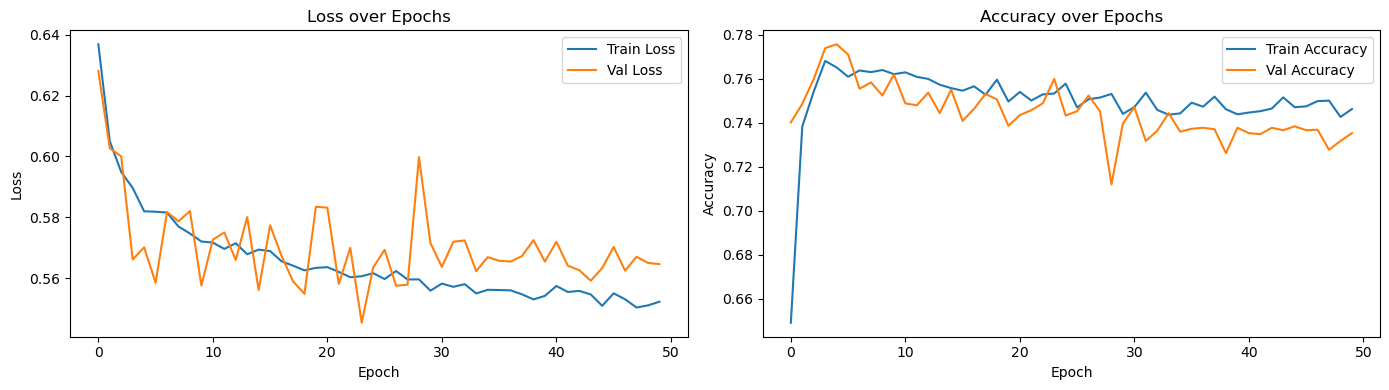

In [31]:
# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

In [32]:
# Evaluate on validation set
y_prob_nn_val = model.predict(X_full_val)
y_pred_nn_val = (y_prob_nn_val >= 0.5).astype(int)

evaluate_model("Neural Network Validation", y_val, y_pred_nn_val, y_prob_nn_val)

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 697us/step

Neural Network Validation Test Results
              precision    recall  f1-score   support

  No Default       0.88      0.76      0.82      3505
     Default       0.43      0.64      0.51       995

    accuracy                           0.74      4500
   macro avg       0.66      0.70      0.67      4500
weighted avg       0.78      0.74      0.75      4500

AUC-ROC: 0.7758


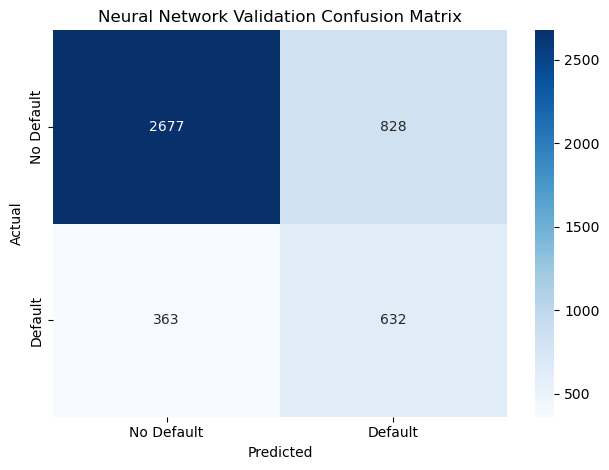

In [33]:
# Confusion matrix
cm = confusion_matrix(y_val, y_pred_nn_val)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Default', 'Default'],
            yticklabels=['No Default', 'Default'])
plt.title('Neural Network Validation Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

### Hyperparameter tuning

In [34]:
from tensorflow.keras.callbacks import EarlyStopping

# Rebuild with same architecture but better training strategy
model_v2 = keras.Sequential([
    layers.Input(shape=(X_full_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

# Lower learning rate gives more careful gradient updates
model_v2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# EarlyStopping monitors val_loss and stops if it stops improving
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True  # rolls back to best epoch automatically
)

history_v2 = model_v2.fit(
    X_full_train, y_train,
    validation_data=(X_full_val, y_val),
    epochs=100,           # allow more epochs since early stopping will cut it short
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)


y_prob_nn_v2 = model_v2.predict(X_full_val)

Epoch 1/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6442 - loss: 0.6460 - val_accuracy: 0.7462 - val_loss: 0.6224
Epoch 2/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7107 - loss: 0.6181 - val_accuracy: 0.7731 - val_loss: 0.5949
Epoch 3/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7412 - loss: 0.6033 - val_accuracy: 0.7653 - val_loss: 0.6035
Epoch 4/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7531 - loss: 0.5971 - val_accuracy: 0.7738 - val_loss: 0.5862
Epoch 5/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7557 - loss: 0.5939 - val_accuracy: 0.7800 - val_loss: 0.5676
Epoch 6/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7636 - loss: 0.5868 - val_accuracy: 0.7753 - val_loss: 0.5709
Epoch 7/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7624 - loss: 0.5846 - val_accuracy: 0.7727 - val_loss: 0.5694
Epoch 8/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7633 - loss: 0.5814 - val_accu

In [35]:
from sklearn.metrics import f1_score
import numpy as np

# Use probabilities from the already-trained model_v2
thresholds = np.arange(0.25, 0.55, 0.05)
results = []

for t in thresholds:
    y_pred_t = (y_prob_nn_v2 >= t).astype(int)
    f1_default = f1_score(y_val, y_pred_t, pos_label=1)
    recall_default = classification_report(y_val, y_pred_t, output_dict=True)['1']['recall']
    precision_default = classification_report(y_val, y_pred_t, output_dict=True)['1']['precision']
    results.append({
        'threshold': round(t, 2),
        'default_f1': round(f1_default, 4),
        'default_recall': round(recall_default, 4),
        'default_precision': round(precision_default, 4)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 threshold  default_f1  default_recall  default_precision
      0.25      0.4036          0.9638             0.2553
      0.30      0.4231          0.9126             0.2754
      0.35      0.4549          0.8683             0.3081
      0.40      0.4872          0.7719             0.3559
      0.45      0.5074          0.6372             0.4215
      0.50      0.5252          0.5910             0.4727
      0.55      0.5248          0.5266             0.5230


In [36]:
# Pick best threshold by Default F1
best_t = results_df.loc[results_df['default_f1'].idxmax(), 'threshold']
print(f"\nBest threshold by Default F1: {best_t}")


y_pred_nn_final = (y_prob_nn_v2 >= best_t).astype(int)
evaluate_model(f"Neural Network V2 (threshold={best_t})", y_val, y_pred_nn_final, y_prob_nn_v2)


Best threshold by Default F1: 0.5

Neural Network V2 (threshold=0.5) Test Results
              precision    recall  f1-score   support

  No Default       0.88      0.81      0.84      3505
     Default       0.47      0.59      0.53       995

    accuracy                           0.76      4500
   macro avg       0.67      0.70      0.68      4500
weighted avg       0.79      0.76      0.77      4500

AUC-ROC: 0.7730


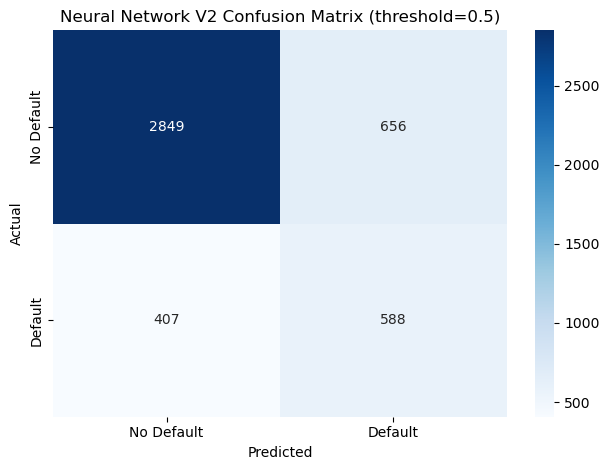

In [37]:
cm_final = confusion_matrix(y_val, y_pred_nn_final)
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Default', 'Default'],
            yticklabels=['No Default', 'Default'])
plt.title(f'Neural Network V2 Confusion Matrix (threshold={best_t})')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

### Neural Network Results & Interpretation

The initial neural network architecture (two hidden layers of 64 and 32 units with ReLU activations, 30% dropout, sigmoid output, trained with Adam at the default learning rate over 5,000 epochs with computed class weights) showed learning curves that plateaued and degraded after approximately epoch 25–30, motivating a second architecture (Model V2) with a reduced learning rate of 0.0005 and EarlyStopping (patience=7, restoring best weights), which trained for only 28 epochs before stopping. Threshold tuning on the validation set was then performed across values from 0.25 to 0.55: at threshold=0.25, default recall was 0.9638 but F1 was only 0.4036, while at threshold=0.50, default F1 peaked at 0.5252 with recall of 0.5910 and precision of 0.4727; the best F1 across thresholds was achieved at 0.50, which was selected as the final operating threshold.

On the final test set at the threshold of 0.50, the Neural Network achieved an accuracy of 76.4%, an AUC-ROC of 0.7703, a default precision of 0.47, a default recall of 0.59, and a default F1 of 0.53. These results place it competitively between the Random Forest and KNN — it demonstrates strong discriminatory power nearly matching the Random Forest in AUC, but its default precision lags behind the Random Forest (0.47 vs. 0.52), and the added complexity of architecture design, training time, class weighting, and threshold selection did not translate into a meaningful performance advantage. While the network benefits from automatic feature interaction learning through its layers, the modest training size of 21,000 rows and 23 features likely constrains its advantage over the simpler ensemble approach, which more directly exploits the dominant repayment history signal structure.

## Overall Comparison 


KNN Final Test Test Results
              precision    recall  f1-score   support

  No Default       0.88      0.73      0.80      3504
     Default       0.40      0.64      0.49       996

    accuracy                           0.71      4500
   macro avg       0.64      0.68      0.65      4500
weighted avg       0.77      0.71      0.73      4500

AUC-ROC: 0.7492


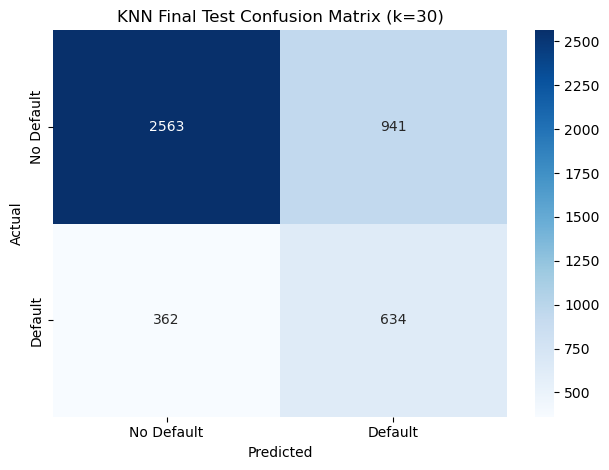

In [38]:
# ── Final Test Evaluation ─────────────────────────────────────────

# KNN
y_pred_knn_test = knn_smote.predict(X_knn_test)
y_prob_knn_test = knn_smote.predict_proba(X_knn_test)[:, 1]
evaluate_model("KNN Final Test", y_test, y_pred_knn_test, y_prob_knn_test)

cm_knn_test = confusion_matrix(y_test, y_pred_knn_test)
sns.heatmap(cm_knn_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Default', 'Default'],
            yticklabels=['No Default', 'Default'])
plt.title(f'KNN Final Test Confusion Matrix (k={best_k_sm})')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()



Random Forest Final Test Test Results
              precision    recall  f1-score   support

  No Default       0.88      0.85      0.86      3504
     Default       0.52      0.58      0.55       996

    accuracy                           0.79      4500
   macro avg       0.70      0.71      0.71      4500
weighted avg       0.80      0.79      0.79      4500

AUC-ROC: 0.7771


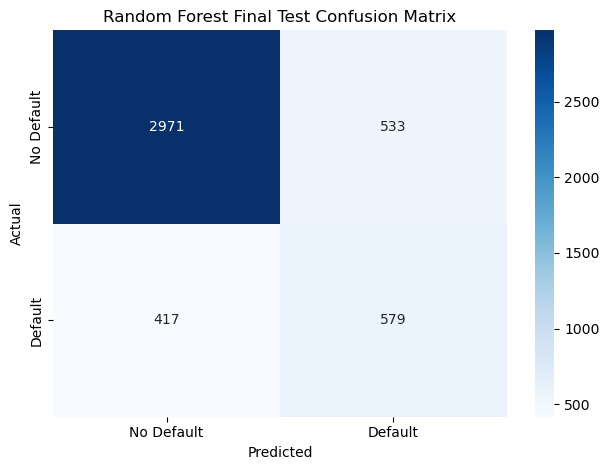

In [39]:
# Random Forest
y_pred_rf_test = rf_tuned.predict(X_full_test)
y_prob_rf_test = rf_tuned.predict_proba(X_full_test)[:, 1]
evaluate_model("Random Forest Final Test", y_test, y_pred_rf_test, y_prob_rf_test)

cm_rf_test = confusion_matrix(y_test, y_pred_rf_test)
sns.heatmap(cm_rf_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Default', 'Default'],
            yticklabels=['No Default', 'Default'])
plt.title('Random Forest Final Test Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()


141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 651us/step

Neural Network Final Test (threshold=0.5) Test Results
              precision    recall  f1-score   support

  No Default       0.88      0.81      0.84      3504
     Default       0.47      0.59      0.53       996

    accuracy                           0.76      4500
   macro avg       0.67      0.70      0.68      4500
weighted avg       0.79      0.76      0.77      4500

AUC-ROC: 0.7711


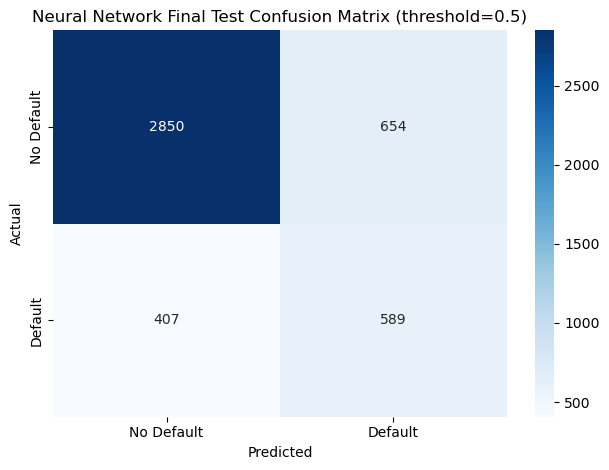

In [40]:
# Neural Network
y_prob_nn_test = model_v2.predict(X_full_test)
y_pred_nn_test = (y_prob_nn_test >= best_t).astype(int)
evaluate_model(f"Neural Network Final Test (threshold={best_t})", y_test, y_pred_nn_test, y_prob_nn_test)

cm_nn_test = confusion_matrix(y_test, y_pred_nn_test)
sns.heatmap(cm_nn_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Default', 'Default'],
            yticklabels=['No Default', 'Default'])
plt.title(f'Neural Network Final Test Confusion Matrix (threshold={best_t})')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()


In [41]:
# Summary comparison table
from sklearn.metrics import roc_auc_score, accuracy_score

comparison = pd.DataFrame({
    'Model': ['KNN (SMOTE)', 'Random Forest (Tuned)', f'Neural Network (t={best_t})'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn_test),
        accuracy_score(y_test, y_pred_rf_test),
        accuracy_score(y_test, y_pred_nn_test)
    ],
    'AUC-ROC': [
        roc_auc_score(y_test, y_prob_knn_test),
        roc_auc_score(y_test, y_prob_rf_test),
        roc_auc_score(y_test, y_prob_nn_test)
    ],
    'Default Recall': [
        classification_report(y_test, y_pred_knn_test, output_dict=True)['1']['recall'],
        classification_report(y_test, y_pred_rf_test, output_dict=True)['1']['recall'],
        classification_report(y_test, y_pred_nn_test, output_dict=True)['1']['recall']
    ],
    'Default Precision': [
        classification_report(y_test, y_pred_knn_test, output_dict=True)['1']['precision'],
        classification_report(y_test, y_pred_rf_test, output_dict=True)['1']['precision'],
        classification_report(y_test, y_pred_nn_test, output_dict=True)['1']['precision']
    ],
    'Default F1': [
        classification_report(y_test, y_pred_knn_test, output_dict=True)['1']['f1-score'],
        classification_report(y_test, y_pred_rf_test, output_dict=True)['1']['f1-score'],
        classification_report(y_test, y_pred_nn_test, output_dict=True)['1']['f1-score']
    ]
}).round(4)

print(comparison.to_string(index=False))


                 Model  Accuracy  AUC-ROC  Default Recall  Default Precision  Default F1
           KNN (SMOTE)    0.7104   0.7492          0.6365             0.4025      0.4932
 Random Forest (Tuned)    0.7889   0.7771          0.5813             0.5207      0.5493
Neural Network (t=0.5)    0.7642   0.7711          0.5914             0.4739      0.5261


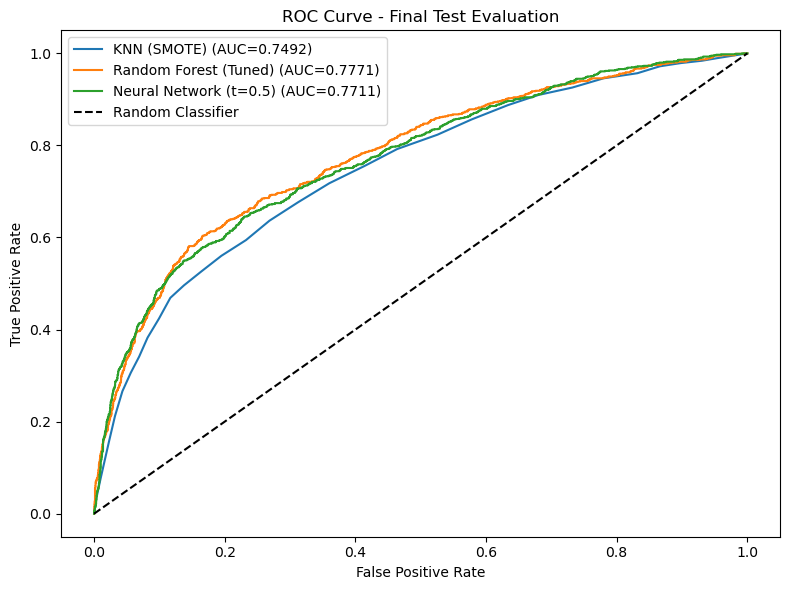

In [42]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, y_prob in [
    (f'KNN (SMOTE)', y_prob_knn_test),
    ('Random Forest (Tuned)', y_prob_rf_test),
    (f'Neural Network (t={best_t})', y_prob_nn_test)
]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Final Test Evaluation')
plt.legend()
plt.tight_layout()
plt.show()


## Conclusion

Across all three models evaluated on the held-out test set of 4,500 observations, the Tuned Random Forest emerged as the strongest overall performer, achieving the highest accuracy (78.9%), AUC-ROC (0.7771), default precision (0.52), and default F1 (0.55), making it the best choice for predicting credit card default on this dataset. The Neural Network (AUC-ROC 0.7703, default F1 0.53) was a close second in discrimination ability, but its marginal gains over the Random Forest did not justify the additional complexity of architecture design, threshold tuning, and extended training time. KNN with SMOTE ranked last in accuracy (71.0%) and AUC-ROC (0.7492), though it achieved the highest default recall of the three models (0.6365), indicating it is the most aggressive at flagging potential defaulters — at the direct cost of the lowest default precision (0.40) and the highest false-positive rate.

A central takeaway across all models is that the 77.9%/22.1% class imbalance posed the primary modeling challenge, and each model addressed it differently — KNN via SMOTE synthetic oversampling, the Random Forest via balanced class weights, and the Neural Network via computed class weights — with the Random Forest's approach proving the most effective at balancing precision and recall for the minority class without inflating false positives. The ROC curves confirm that the Random Forest and Neural Network are nearly indistinguishable in discriminative power across all classification thresholds, while KNN consistently trails, particularly at low false-positive rates where the gap is most pronounced. PAY_0 (most recent repayment status) emerged as the single most dominant feature across all models, and future improvements could include more granular threshold calibration for the neural network, stacking or blending the Random Forest and Neural Network outputs, or exploring gradient boosting methods such as XGBoost which may further improve the precision-recall balance for the default class.